1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
Predicted Class: Sunflower
Probability: 1.0000


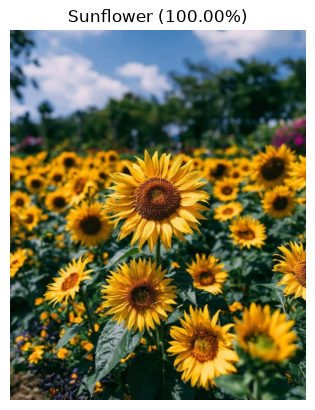

In [5]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

path = 'predict'
model_save_path = 'model_trained_data.h5'
class_labels = {0: 'Sunflower', 1: 'Daisy'}


model = tf.keras.models.load_model(model_save_path, compile=False)

def test_image(img_name):
   
    img_path = os.path.join(path, img_name)
    original_img = cv2.imread(img_path) 
    
    if original_img is None:
        print(f"이미지를 찾을 수 없습니다: {img_path}")
        return
        
   
    resized_img = cv2.resize(original_img, (128, 128)) / 255.0
    input_data = resized_img.reshape(1, 128, 128, 3) 

  
    predictions = model.predict(input_data)
    raw_probability = predictions[0][0] 

    if raw_probability > 0.5:
        class_index = 1  # Daisy
        probability = raw_probability  
    else:
        class_index = 0  # Sunflower
        probability = 1.0 - raw_probability  

   
    print(f"Predicted Class: {class_labels.get(class_index)}")
    print(f"Probability: {probability:.4f}")

   
    display_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    plt.imshow(display_img)
    plt.title(f"{class_labels.get(class_index)} ({probability:.2%})")
    plt.axis('off')
    plt.show()


test_image('0-12.jpeg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Predicted Class: Daisy
Probability: 1.0000


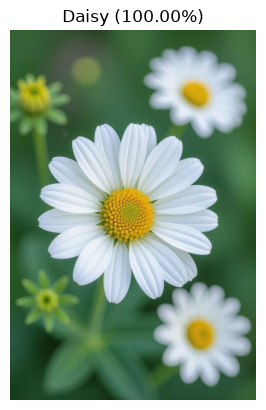

In [6]:
test_image('1-3.jpeg')